# Practical Exercise: Implementing an M/M/1 Queue in SimPy

## Objective
In this practical exercise, you will implement a simple M/M/1 queueing system using SimPy. This will help you understand the fundamentals of Discrete Event Simulation (DES).

## What is an M/M/1 Queue?
An M/M/1 queue is a basic queueing model with:
- **M** (Memoryless/Markovian): Customer arrivals follow a Poisson process
- **M** (Memoryless/Markovian): Service times follow an exponential distribution
- **1**: Single server

## Prerequisites
- Basic Python knowledge
- This notebook, open on the course site (or in Google Colab or Jupyter on your own computer)
- Understanding of arrival rates (λ) and service rates (μ)

---

## Instructions

### Step 1: Open the notebook
You are already in it: work through the steps below, running each code cell in turn.
(Prefer to start from a blank notebook, for example in [Google Colab](https://colab.research.google.com/)? Create a new notebook and copy each code cell across as you go.)

### Step 2: Install SimPy
Run the code cell below first. It installs the SimPy library (`%pip install simpy`); in Google Colab or on your own computer the same line works.

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install simpy

### Step 3: Import Required Libraries
In a new cell, import the necessary libraries:

In [2]:
import simpy
import random
import numpy as np
import matplotlib.pyplot as plt

### Step 4: Set Simulation Parameters
Define the parameters for your M/M/1 queue:

In [3]:
# Simulation parameters
RANDOM_SEED = 42
SIM_TIME = 100        # Simulation time (hours)
ARRIVAL_RATE = 5      # λ: Average arrivals per hour
SERVICE_RATE = 6      # μ: Average service rate per hour

# Calculate mean inter-arrival time and service time
MEAN_INTER_ARRIVAL = 1.0 / ARRIVAL_RATE
MEAN_SERVICE_TIME = 1.0 / SERVICE_RATE

# Calculate utilisation (ρ = λ/μ)
UTILISATION = ARRIVAL_RATE / SERVICE_RATE
print(f"System Utilisation (ρ): {UTILISATION:.2f}")

System Utilisation (ρ): 0.83


**Note**: For a stable queue, utilisation (ρ) must be less than 1.

### Step 5: Create the Customer Generator
Create a function that generates customers arriving at the system:

In [4]:
def customer_generator(env, arrival_rate, service_rate, server):
    """Generate customers arriving at random intervals."""
    customer_id = 0
    while True:
        # Wait for next customer
        inter_arrival_time = random.expovariate(arrival_rate)
        yield env.timeout(inter_arrival_time)
        
        customer_id += 1
        # Create a customer process
        env.process(customer(env, f'Customer_{customer_id}', service_rate, server))

### Step 6: Create the Customer Process
Define what happens when a customer arrives and gets served:

In [5]:
def customer(env, name, service_rate, server):
    """Customer arrives, requests service, gets served, and leaves."""
    arrival_time = env.now
    print(f'{name} arrives at {arrival_time:.2f}')
    
    with server.request() as request:
        # Wait for the server
        yield request
        
        wait_time = env.now - arrival_time
        print(f'{name} enters service at {env.now:.2f} (waited {wait_time:.2f})')
        
        # Service time
        service_time = random.expovariate(service_rate)
        yield env.timeout(service_time)
        
        print(f'{name} departs at {env.now:.2f} (service time: {service_time:.2f})')

### Step 7: Run the Simulation
Set up and run the simulation environment:

In [6]:
# Set random seed for reproducibility
random.seed(RANDOM_SEED)

# Create environment
env = simpy.Environment()

# Create server (Resource with capacity 1)
server = simpy.Resource(env, capacity=1)

# Start the customer generator process
env.process(customer_generator(env, ARRIVAL_RATE, SERVICE_RATE, server))

# Run the simulation
print("=== Simulation Start ===\n")
env.run(until=SIM_TIME)
print("\n=== Simulation End ===")

=== Simulation Start ===

Customer_1 arrives at 0.20
Customer_1 enters service at 0.20 (waited 0.00)
Customer_2 arrives at 0.21
Customer_1 departs at 0.26 (service time: 0.05)
Customer_2 enters service at 0.26 (waited 0.05)
Customer_3 arrives at 0.26
Customer_2 departs at 0.48 (service time: 0.22)
Customer_3 enters service at 0.48 (waited 0.22)
Customer_4 arrives at 0.49
Customer_5 arrives at 0.50
Customer_6 arrives at 0.61
Customer_7 arrives at 0.62
Customer_8 arrives at 0.67
Customer_9 arrives at 0.81
Customer_10 arrives at 0.81
Customer_3 departs at 0.85 (service time: 0.37)
Customer_4 enters service at 0.85 (waited 0.37)
Customer_11 arrives at 0.86
Customer_12 arrives at 1.02
Customer_4 departs at 1.03 (service time: 0.17)
Customer_5 enters service at 1.03 (waited 0.52)
Customer_13 arrives at 1.07
Customer_5 departs at 1.17 (service time: 0.15)
Customer_6 enters service at 1.17 (waited 0.56)
Customer_6 departs at 1.18 (service time: 0.00)
Customer_7 enters service at 1.18 (waited 0

### Step 8: Add Data Collection (Extension)
To analyse the queue, modify your code to collect statistics:

In [7]:
# Lists to store data
wait_times = []
service_times = []
system_times = []

def customer_with_stats(env, name, service_rate, server):
    """Customer process that collects statistics."""
    arrival_time = env.now
    
    with server.request() as request:
        yield request
        
        wait_time = env.now - arrival_time
        wait_times.append(wait_time)
        
        service_time = random.expovariate(service_rate)
        service_times.append(service_time)
        
        yield env.timeout(service_time)
        
        system_time = env.now - arrival_time
        system_times.append(system_time)

def customer_generator_with_stats(env, arrival_rate, service_rate, server):
    """Generate customers and collect stats."""
    customer_id = 0
    while True:
        inter_arrival_time = random.expovariate(arrival_rate)
        yield env.timeout(inter_arrival_time)
        
        customer_id += 1
        env.process(customer_with_stats(env, f'Customer_{customer_id}', service_rate, server))

### Step 9: Run and Analyse Results
Run the simulation with statistics:

In [8]:
# Reset data
wait_times = []
service_times = []
system_times = []

# Set random seed
random.seed(RANDOM_SEED)

# Create new environment
env = simpy.Environment()
server = simpy.Resource(env, capacity=1)

# Start process
env.process(customer_generator_with_stats(env, ARRIVAL_RATE, SERVICE_RATE, server))

# Run simulation
env.run(until=SIM_TIME)

# Display statistics
print(f"\n=== Simulation Statistics ===")
print(f"Total customers served: {len(wait_times)}")
print(f"Average wait time: {np.mean(wait_times):.3f}")
print(f"Average service time: {np.mean(service_times):.3f}")
print(f"Average time in system: {np.mean(system_times):.3f}")
print(f"Max wait time: {np.max(wait_times):.3f}")
print(f"Min wait time: {np.min(wait_times):.3f}")


=== Simulation Statistics ===
Total customers served: 501
Average wait time: 1.558
Average service time: 0.186
Average time in system: 1.746
Max wait time: 4.145
Min wait time: 0.000


### Step 10: Visualise Results
Create plots to visualise the queue performance:

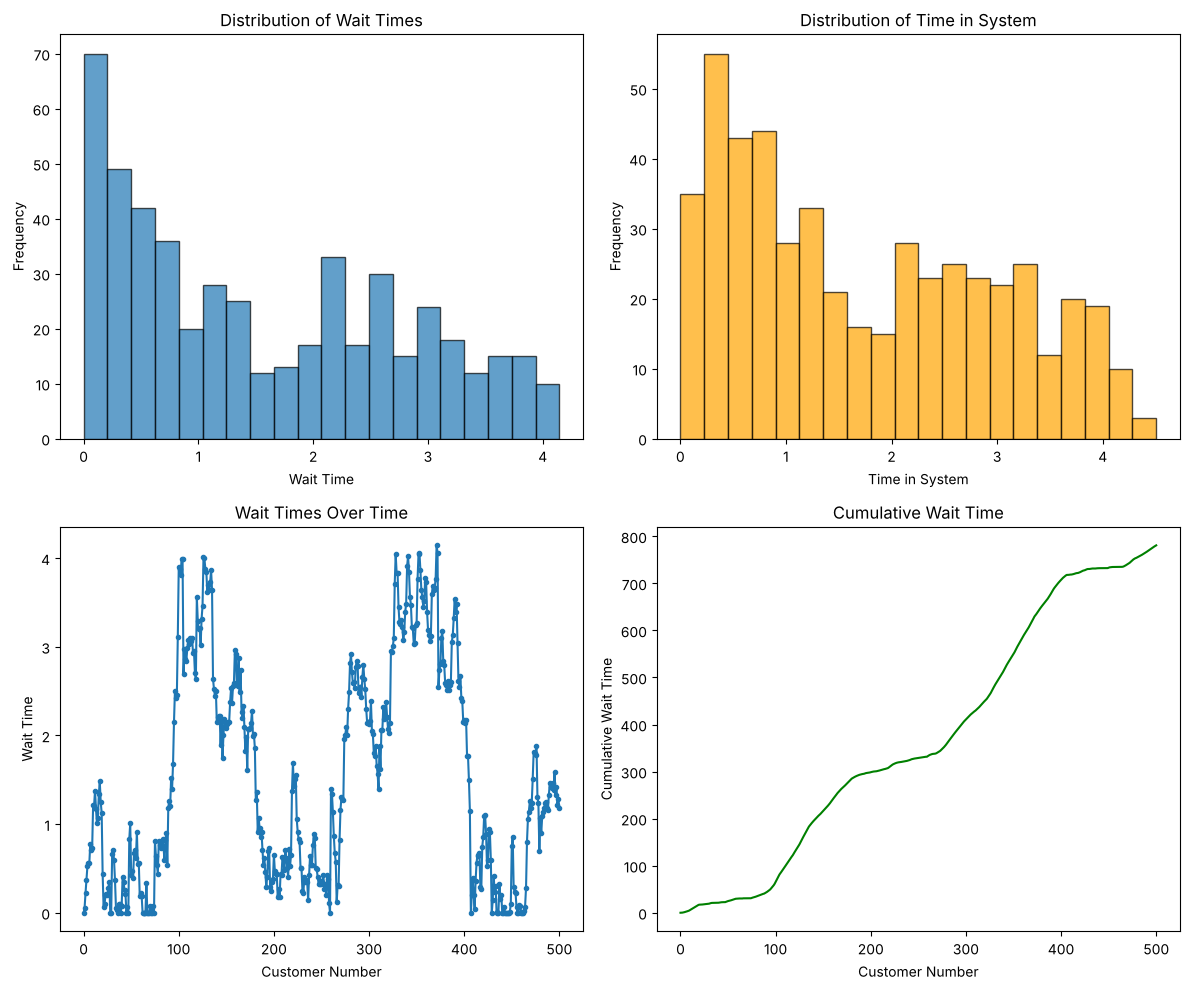

In [9]:
# Create visualisations
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Wait times histogram
axes[0, 0].hist(wait_times, bins=20, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Distribution of Wait Times')
axes[0, 0].set_xlabel('Wait Time')
axes[0, 0].set_ylabel('Frequency')

# System times histogram
axes[0, 1].hist(system_times, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].set_title('Distribution of Time in System')
axes[0, 1].set_xlabel('Time in System')
axes[0, 1].set_ylabel('Frequency')

# Wait times over time
axes[1, 0].plot(wait_times, marker='o', linestyle='-', markersize=3)
axes[1, 0].set_title('Wait Times Over Time')
axes[1, 0].set_xlabel('Customer Number')
axes[1, 0].set_ylabel('Wait Time')

# Cumulative wait times
axes[1, 1].plot(np.cumsum(wait_times), color='green')
axes[1, 1].set_title('Cumulative Wait Time')
axes[1, 1].set_xlabel('Customer Number')
axes[1, 1].set_ylabel('Cumulative Wait Time')

plt.tight_layout()
plt.show()

---

## Tasks to Complete

1. **Basic Implementation**: 
   - Follow Steps 1-7 to implement the basic M/M/1 queue
   - Run the simulation and observe the output

2. **Add Statistics** (Steps 8-9):
   - Modify your code to collect wait times and service times
   - Calculate average performance metrics

3. **Visualisation** (Step 10):
   - Create plots to visualise the queue behavior

4. **Experiment**:
   - Try different values of `ARRIVAL_RATE` and `SERVICE_RATE`
   - What happens when utilisation (ρ) approaches 1?
   - What happens when ρ > 1?

5. **Compare with Theory**:
   - Calculate theoretical average wait time: **W_q = ρ / (μ(1-ρ))**
   - Compare with your simulation results
   - Calculate theoretical average time in system: **W = 1 / (μ - λ)**
   - Compare with your simulation results

---

## Challenge Questions

1. How does increasing the arrival rate affect average wait time?
2. What happens to the queue when the system is under-utilised (ρ < 0.5)?
3. What happens when the system is heavily utilised (ρ > 0.9)?
4. How long should you run the simulation to get stable average results?

---

## Tips

- Start with a **low utilisation** (e.g., ρ = 0.5) to ensure stability
- Use a **longer simulation time** (e.g., 500 or 1000) for more accurate statistics
- Remember: **ρ must be < 1** for a stable queue
- The **random seed** ensures reproducible results

---

## Expected Outcome

By the end of this practical, you should:
- Have a working M/M/1 queue simulation in a notebook
- Understand how to use SimPy for DES
- Be able to collect and analyse simulation statistics
- Understand the relationship between arrival rate, service rate, and utilisation